# 09 — Análise por subgrupos demográficos

**TCC UNIP 2026** · Etapa 9 de 9 do pipeline · Requisito RNF03 (Seção 4.2.2); resultados na Seção 5.7.7 do trabalho escrito.

**Objetivo:** calcular a acurácia e a sensibilidade para melanoma por sexo e por faixa etária no conjunto de teste e empacotar os resultados.

**Entradas:**
- `modelo_resnet50.pt`, `modelo_efficientnet_b0.pt` e `config_final.json` (notebook 06)
- `test.csv` e imagens de teste (notebook 03)

**Saídas:**
- `equidade/` (métricas por subgrupo, gráficos e `resumo_disparidades.csv`)
- `resultados_tcc.zip` (figuras, tabelas e JSONs)

Antes de executar: no Colab, selecione *Ambiente de execução → Alterar tipo de ambiente de execução → GPU* (necessário a partir do notebook 05). As saídas exibidas foram preservadas da execução original do notebook único.

In [ ]:
# Parâmetro: True usa o Google Drive para guardar os arquivos entre notebooks;
# False usa só o disco da sessão atual. Quando o notebook é executado pelo
# 00_executar_todos.ipynb, vale o valor definido lá.
if "USAR_DRIVE" not in globals():
    USAR_DRIVE = True


In [ ]:
# ============================================================
# PERSISTÊNCIA ENTRE NOTEBOOKS (Google Drive)
# ============================================================
# Cada notebook roda em uma sessão própria do Colab. Para que os arquivos gerados por um
# notebook fiquem disponíveis para os seguintes, a pasta /content/data é ligada a uma
# pasta no Google Drive. O valor de USAR_DRIVE é definido na célula anterior.
PASTA_DRIVE = "/content/drive/MyDrive/TCC_UNIP/data"

import os
if USAR_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    os.makedirs(PASTA_DRIVE, exist_ok=True)
    if not os.path.islink("/content/data"):
        if os.path.isdir("/content/data"):
            if os.listdir("/content/data"):
                raise RuntimeError("/content/data já contém arquivos: mova-os para a pasta do Drive antes de continuar.")
            os.rmdir("/content/data")
        os.symlink(PASTA_DRIVE, "/content/data")
print("Pasta de dados:", os.path.realpath("/content/data"))


## Funções do pipeline de dados (reutilizadas do notebook 04)

In [ ]:
# [Célula reutilizada de 03_preprocessamento.ipynb]
import os
import cv2
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split
from tqdm import tqdm


In [ ]:
# [Célula reutilizada de 03_preprocessamento.ipynb]
SEED = 42
PROPORCAO_TREINO = 0.70
PROPORCAO_VAL = 0.15
PROPORCAO_TESTE = 0.15

# Mantido por compatibilidade com a estrutura original. Na versão corrigida, imagens sem
# lesion_id são mantidas e viram grupos próprios, salvo quando ligadas por pHash a duplicatas.
INCLUIR_SEM_LESION_ID = True

In [ ]:
# [Célula reutilizada de 04_pipeline_dados_pytorch.ipynb]
import pandas as pd
import cv2
import torch
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2

In [ ]:
# [Célula reutilizada de 04_pipeline_dados_pytorch.ipynb]
SAIDA_BASE = "/content/data/processed"
MEAN_IMAGENET = [0.485, 0.456, 0.406]
STD_IMAGENET = [0.229, 0.224, 0.225]
BATCH_SIZE = 32
NUM_WORKERS = 2   # o Colab tem 2 CPUs; mais workers que isso só atrapalha (ver aviso do DataLoader)

# Modo de teste rápido (opcional): use p.ex. 0.05 para treinar/avaliar com ~5% das imagens
# e conferir se o notebook inteiro roda, antes de gastar horas de GPU. None = usa tudo.
FRACAO_DADOS_DEBUG = None

In [ ]:
# [Célula reutilizada de 04_pipeline_dados_pytorch.ipynb]
# ============================================================
# TRANSFORMS
# ============================================================
# ATENÇÃO (teste de cor): o ColorJitter do Albumentations, quando 'hue' não é informado, aplica
# uma rotação de MATIZ por padrão (nas versões 2.x: até ±0.5 do círculo cromático, i.e. qualquer cor).
# Isso muda a cor da lesão — um sinal clínico central (critério "C" do ABCDE) — em metade das imagens.
# Esta é a configuração da versão anterior e é mantida como variante "original" para comparação.
train_transform = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, p=0.5),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.1, rotate_limit=15, p=0.3),
    A.Normalize(mean=MEAN_IMAGENET, std=STD_IMAGENET),
    ToTensorV2(),
])

# Val/teste: SEM augmentation aleatório — só normalização, para avaliação justa e reprodutível
eval_transform = A.Compose([
    A.Normalize(mean=MEAN_IMAGENET, std=STD_IMAGENET),
    ToTensorV2(),
])

# ------------------------------------------------------------
# Variantes de augmentation de COR (usadas no "Teste de alterações de cor")
#   "original"         -> a configuração acima (brilho, contraste, saturação E matiz padrão do Albumentations)
#   "brilho_contraste" -> só brilho e contraste (±20%); saturação e matiz FIXOS (cor da lesão preservada)
#   "sem_cor"          -> nenhuma alteração de cor (só flips/rotações/escala)
# ------------------------------------------------------------
def construir_train_transform(variante_cor="original"):
    if variante_cor == "original":
        return train_transform
    if variante_cor == "brilho_contraste":
        cor = [A.ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2),
                             saturation=(1.0, 1.0), hue=(0.0, 0.0), p=0.5)]
    elif variante_cor == "sem_cor":
        cor = []
    else:
        raise ValueError(f"Variante de cor desconhecida: {variante_cor}")
    return A.Compose([
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.5),
        A.RandomRotate90(p=0.5),
        *cor,
        A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.1, rotate_limit=15, p=0.3),
        A.Normalize(mean=MEAN_IMAGENET, std=STD_IMAGENET),
        ToTensorV2(),
    ])

TRAIN_TRANSFORMS = {v: construir_train_transform(v)
                    for v in ["original", "brilho_contraste", "sem_cor"]}

In [ ]:
# [Célula reutilizada de 04_pipeline_dados_pytorch.ipynb]
# ============================================================
# DATASET
# ============================================================
from PIL import Image, ImageEnhance

def aplicar_perturbacao_cor(img_rgb, brilho=0.0, contraste=0.0, saturacao=0.0, matiz=0.0):
    """Perturbação DETERMINÍSTICA de cor (usada só na avaliação de robustez, nunca no treino).
    brilho/contraste/saturacao: variação relativa (0.2 = +20%, -0.2 = -20%).
    matiz: fração do círculo cromático (0.1 = 36 graus)."""
    pil = Image.fromarray(img_rgb)
    if brilho:
        pil = ImageEnhance.Brightness(pil).enhance(1.0 + brilho)
    if contraste:
        pil = ImageEnhance.Contrast(pil).enhance(1.0 + contraste)
    if saturacao:
        pil = ImageEnhance.Color(pil).enhance(1.0 + saturacao)
    if matiz:
        h, s, v = pil.convert("HSV").split()
        deslocamento = int(round(matiz * 255))
        h = h.point(lambda x: (x + deslocamento) % 256)
        pil = Image.merge("HSV", (h, s, v)).convert("RGB")
    return np.array(pil)


class DermatoDataset(Dataset):
    def __init__(self, dataframe, mapa_classes, transform=None, perturbacao=None):
        self.df = dataframe.reset_index(drop=True)
        self.mapa_classes = mapa_classes
        self.transform = transform
        self.perturbacao = perturbacao   # dict p/ aplicar_perturbacao_cor (None = sem perturbação)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        linha = self.df.iloc[idx]
        img = cv2.imread(linha["caminho_processado"])
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        if self.perturbacao:
            img = aplicar_perturbacao_cor(img, **self.perturbacao)

        if self.transform:
            img = self.transform(image=img)["image"]

        rotulo = self.mapa_classes[linha["classe"]]
        return img, rotulo

In [ ]:
# [Célula reutilizada de 04_pipeline_dados_pytorch.ipynb]
# ============================================================
# CRIAÇÃO DOS DATALOADERS
# ============================================================
# Qual versão das imagens é usada por padrão: "com_dullrazor" (train.csv...) ou "sem_dullrazor".
# A célula de seleção da configuração final (mais adiante) atualiza este valor.
DADOS_ATIVOS = "com_dullrazor"

def caminho_csv_split(split, dados):
    sufixo = "" if dados == "com_dullrazor" else f"_{dados}"
    return f"{SAIDA_BASE}/{split}{sufixo}.csv"

def _ler_split(split, dados):
    df = pd.read_csv(caminho_csv_split(split, dados), low_memory=False)
    if FRACAO_DADOS_DEBUG:
        df = (df.groupby("classe", group_keys=False)
                .apply(lambda g: g.sample(n=max(2, int(len(g) * FRACAO_DADOS_DEBUG)),
                                          random_state=SEED)
                       if len(g) > 2 else g))
    return df

def criar_dataloaders(batch_size=BATCH_SIZE, dados=None, variante_cor="original"):
    dados = dados or DADOS_ATIVOS
    df_treino = _ler_split("train", dados)
    df_val = _ler_split("val", dados)
    df_teste = _ler_split("test", dados)

    classes_ordenadas = sorted(df_treino["classe"].unique())
    mapa_classes = {nome: idx for idx, nome in enumerate(classes_ordenadas)}
    print("Mapa de classes:", mapa_classes)
    print(f"Dados: {dados} | augmentation de cor: {variante_cor}")

    ds_treino = DermatoDataset(df_treino, mapa_classes, transform=TRAIN_TRANSFORMS[variante_cor])
    ds_val = DermatoDataset(df_val, mapa_classes, transform=eval_transform)
    ds_teste = DermatoDataset(df_teste, mapa_classes, transform=eval_transform)

    pin = torch.cuda.is_available()
    train_loader = DataLoader(ds_treino, batch_size=batch_size, shuffle=True,
                               num_workers=NUM_WORKERS, pin_memory=pin,
                               persistent_workers=NUM_WORKERS > 0)
    val_loader = DataLoader(ds_val, batch_size=batch_size, shuffle=False,
                             num_workers=NUM_WORKERS, pin_memory=pin)
    test_loader = DataLoader(ds_teste, batch_size=batch_size, shuffle=False,
                              num_workers=NUM_WORKERS, pin_memory=pin)

    return train_loader, val_loader, test_loader, mapa_classes


def criar_loader_teste(dados=None, perturbacao=None, batch_size=BATCH_SIZE):
    """DataLoader de TESTE (sem augmentation), opcionalmente com perturbação determinística
    de cor — usado na avaliação de robustez a brilho/contraste."""
    dados = dados or DADOS_ATIVOS
    df_treino = _ler_split("train", dados)
    mapa_classes = {n: i for i, n in enumerate(sorted(df_treino["classe"].unique()))}
    ds = DermatoDataset(_ler_split("test", dados), mapa_classes,
                        transform=eval_transform, perturbacao=perturbacao)
    loader = DataLoader(ds, batch_size=batch_size, shuffle=False, num_workers=NUM_WORKERS,
                        pin_memory=torch.cuda.is_available())
    return loader, mapa_classes

In [ ]:
# [Constante definida em 03_preprocessamento.ipynb]
SUBPASTA_SEM_DR = "sem_dullrazor"


In [ ]:
# ============================================================
# VERSÃO DAS IMAGENS DEFINIDA NA CONFIGURAÇÃO FINAL (06_treinamento_fine_tuning.ipynb)
# ============================================================
import json
_caminho_cfg = os.path.join(SAIDA_BASE, "experimentos", "config_final.json")
if os.path.exists(_caminho_cfg):
    with open(_caminho_cfg) as f:
        DADOS_ATIVOS = json.load(f)["config_final"]["dados"]
print("Versão das imagens utilizada:", DADOS_ATIVOS)


### ANÁLISE DE EQUIDADE POR SUBGRUPO (idade, sexo)

Verifica se o desempenho do modelo é homogêneo entre diferentes subgrupos
demográficos, ou se há disparidades que precisam ser discutidas no TCC —
especialmente relevante dado que o próprio referencial teórico do trabalho
já identifica a sub-representação de certos perfis nas bases ISIC/HAM10000
(item 3.3 do método).

Cruza as predições do modelo (na mesma ordem do test.csv, já que o
DataLoader de teste usa shuffle=False) com os metadados demográficos
coletados na fase de EDA.

Pré-requisito: test.csv (de preprocessamento.py) precisa ter colunas de
idade e sexo — o script detecta automaticamente os nomes possíveis.

In [ ]:
import os
import torch
import torch.nn as nn
from torchvision import models
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SAIDA_BASE = "/content/data/processed"
SAIDA_EQUIDADE = os.path.join(SAIDA_BASE, "equidade")
os.makedirs(SAIDA_EQUIDADE, exist_ok=True)

In [ ]:
ARQUITETURAS = ["resnet50", "efficientnet_b0"]

# Limiar de disparidade: diferença de acurácia/sensibilidade entre subgrupos
# acima deste valor é sinalizada como potencialmente preocupante
LIMIAR_DISPARIDADE = 0.10  # 10 pontos percentuais

In [ ]:
# ============================================================
# CARREGAMENTO DO MODELO
# ============================================================
def carregar_modelo(arquitetura, num_classes):
    if arquitetura == "resnet50":
        modelo = models.resnet50(weights=None)
        modelo.fc = nn.Linear(modelo.fc.in_features, num_classes)
    elif arquitetura == "efficientnet_b0":
        modelo = models.efficientnet_b0(weights=None)
        modelo.classifier[1] = nn.Linear(modelo.classifier[1].in_features, num_classes)
    else:
        raise ValueError(f"Arquitetura não suportada: {arquitetura}")

    caminho_checkpoint = os.path.join(SAIDA_BASE, f"modelo_{arquitetura}.pt")
    modelo.load_state_dict(torch.load(caminho_checkpoint, map_location=DEVICE))
    modelo.to(DEVICE)
    modelo.eval()
    return modelo

In [ ]:
# ============================================================
# COLETA DE PREDIÇÕES NA ORDEM EXATA DO test.csv
# (test_loader usa shuffle=False, então a ordem bate com o DataFrame)
# ============================================================
def coletar_predicoes_em_ordem(modelo, test_loader):
    todas_preds, todos_rotulos, todas_confiancas = [], [], []

    with torch.no_grad():
        for imagens, rotulos in test_loader:
            imagens = imagens.to(DEVICE)
            saidas = modelo(imagens)
            probs = torch.softmax(saidas, dim=1).cpu().numpy()
            preds = np.argmax(probs, axis=1)
            confiancas = probs[np.arange(len(preds)), preds]

            todas_preds.extend(preds)
            todos_rotulos.extend(rotulos.numpy())
            todas_confiancas.extend(confiancas)

    return np.array(todas_preds), np.array(todos_rotulos), np.array(todas_confiancas)

In [ ]:
# ============================================================
# DETECÇÃO AUTOMÁTICA DAS COLUNAS DEMOGRÁFICAS
# ============================================================
def detectar_coluna(df, candidatos):
    for c in candidatos:
        if c in df.columns:
            return c
    return None

In [ ]:
def preparar_faixas_etarias(df, col_idade):
    """Agrupa idade em faixas clinicamente relevantes."""
    bins = [0, 20, 40, 60, 80, 150]
    labels = ["0-20", "21-40", "41-60", "61-80", "81+"]
    df["faixa_etaria"] = pd.cut(df[col_idade], bins=bins, labels=labels, right=True)
    return df

In [ ]:
# ============================================================
# CÁLCULO DE MÉTRICAS POR SUBGRUPO
# ============================================================
def calcular_metricas_por_subgrupo(df, coluna_subgrupo, nome_classe_melanoma, idx_melanoma):
    """
    Para cada valor do subgrupo (ex.: 'male'/'female', ou cada faixa etária),
    calcula acurácia geral e sensibilidade específica para melanoma.
    """
    linhas = []

    for valor_subgrupo, grupo in df.groupby(coluna_subgrupo, observed=True):
        if len(grupo) == 0:
            continue

        acuracia = (grupo["predicao"] == grupo["rotulo_verdadeiro"]).mean()

        if idx_melanoma is not None:
            grupo_melanoma_real = grupo[grupo["rotulo_verdadeiro"] == idx_melanoma]
            if len(grupo_melanoma_real) > 0:
                sensibilidade_melanoma = (
                    grupo_melanoma_real["predicao"] == idx_melanoma
                ).mean()
                n_melanoma = len(grupo_melanoma_real)
            else:
                sensibilidade_melanoma = np.nan
                n_melanoma = 0
        else:
            sensibilidade_melanoma = np.nan
            n_melanoma = 0

        linhas.append({
            "subgrupo": valor_subgrupo,
            "n_amostras_total": len(grupo),
            "n_amostras_melanoma": n_melanoma,
            "acuracia_geral": round(float(acuracia), 4),
            f"sensibilidade_{nome_classe_melanoma}": round(float(sensibilidade_melanoma), 4)
            if not np.isnan(sensibilidade_melanoma) else None,
            "confianca_media": round(float(grupo["confianca"].mean()), 4),
        })

    return pd.DataFrame(linhas)

In [ ]:
def sinalizar_disparidades(df_metricas, coluna_metrica, nome_subgrupo, arquitetura):
    """Verifica se a diferença entre o melhor e o pior subgrupo excede o limiar."""
    valores_validos = df_metricas[coluna_metrica].dropna()
    if len(valores_validos) < 2:
        print(f"  [AVISO] Dados insuficientes em '{nome_subgrupo}' para comparar disparidade em '{coluna_metrica}'.")
        return None

    maior = valores_validos.max()
    menor = valores_validos.min()
    diferenca = maior - menor

    subgrupo_maior = df_metricas.loc[df_metricas[coluna_metrica].idxmax(), "subgrupo"]
    subgrupo_menor = df_metricas.loc[df_metricas[coluna_metrica].idxmin(), "subgrupo"]

    if diferenca >= LIMIAR_DISPARIDADE:
        print(f"  [DISPARIDADE DETECTADA] {arquitetura} | {nome_subgrupo} | {coluna_metrica}: "
              f"{subgrupo_maior}={maior:.3f} vs. {subgrupo_menor}={menor:.3f} "
              f"(diferença de {diferenca:.3f}, acima do limiar de {LIMIAR_DISPARIDADE})")
    else:
        print(f"  [OK] {arquitetura} | {nome_subgrupo} | {coluna_metrica}: "
              f"diferença máxima de {diferenca:.3f} (dentro do limiar de {LIMIAR_DISPARIDADE})")

    return {
        "arquitetura": arquitetura,
        "subgrupo_analisado": nome_subgrupo,
        "metrica": coluna_metrica,
        "melhor_subgrupo": subgrupo_maior,
        "melhor_valor": round(float(maior), 4),
        "pior_subgrupo": subgrupo_menor,
        "pior_valor": round(float(menor), 4),
        "diferenca": round(float(diferenca), 4),
        "disparidade_relevante": bool(diferenca >= LIMIAR_DISPARIDADE),
    }

In [ ]:
# ============================================================
# VISUALIZAÇÃO
# ============================================================
def plotar_metricas_por_subgrupo(df_metricas, coluna_metrica, nome_subgrupo, arquitetura):
    plt.figure(figsize=(8, 5))
    df_plot = df_metricas.dropna(subset=[coluna_metrica])
    sns.barplot(data=df_plot, x="subgrupo", y=coluna_metrica, palette="viridis")
    plt.axhline(df_plot[coluna_metrica].mean(), color="red", linestyle="--",
                label=f"Média geral ({df_plot[coluna_metrica].mean():.3f})")
    plt.title(f"{coluna_metrica} por {nome_subgrupo} — {arquitetura}")
    plt.ylim(0, 1)
    plt.legend()
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()

    nome_arquivo = f"equidade_{nome_subgrupo}_{coluna_metrica}_{arquitetura}.png"
    caminho = os.path.join(SAIDA_EQUIDADE, nome_arquivo)
    plt.savefig(caminho, dpi=150)
    plt.show()
    print(f"  Gráfico salvo em: {caminho}")

Carregando metadados do conjunto de teste...
Coluna de idade detectada: age_approx
Coluna de sexo detectada: sex

Carregando DataLoaders...
Mapa de classes: {'carcinoma_basocelular': 0, 'ceratose_actinica': 1, 'ceratose_seborreica': 2, 'dermatofibroma': 3, 'lesao_vascular': 4, 'melanoma': 5, 'nevo_melanocitico': 6}
Dados: com_dullrazor | augmentation de cor: original

Análise de equidade: resnet50

--- Equidade por sexo (sex) ---
subgrupo  n_amostras_total  n_amostras_melanoma  acuracia_geral  sensibilidade_melanoma  confianca_media
  female              1613                  275          0.7068                  0.5418           0.8948
    male              1741                  313          0.7455                  0.5719           0.9004
  [OK] resnet50 | sexo | acuracia_geral: diferença máxima de 0.039 (dentro do limiar de 0.1)
  [OK] resnet50 | sexo | sensibilidade_melanoma: diferença máxima de 0.030 (dentro do limiar de 0.1)


/tmp/ipykernel_960/2094831270.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_plot, x="subgrupo", y=coluna_metrica, palette="viridis")


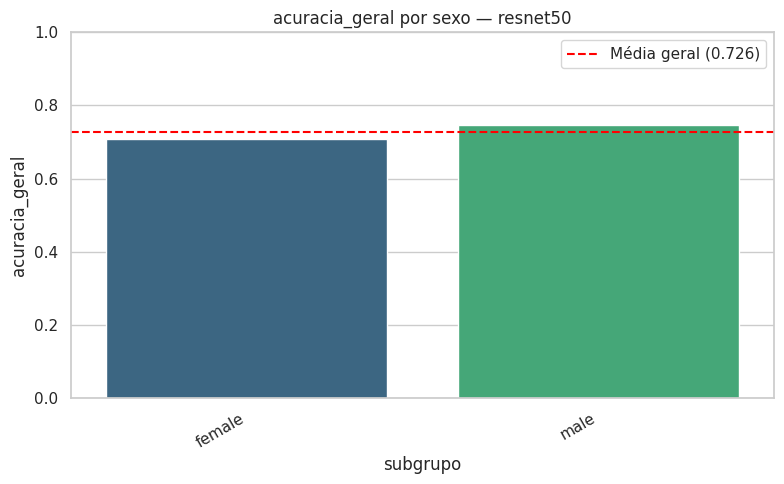

  Gráfico salvo em: /content/data/processed/equidade/equidade_sexo_acuracia_geral_resnet50.png


/tmp/ipykernel_960/2094831270.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_plot, x="subgrupo", y=coluna_metrica, palette="viridis")


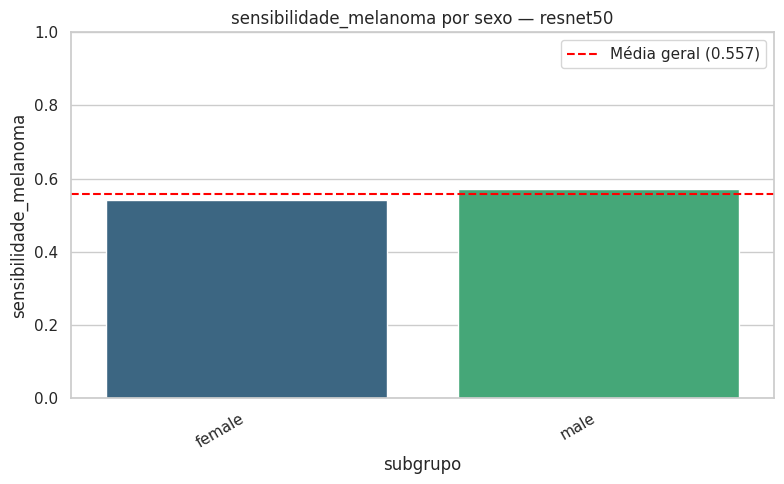

  Gráfico salvo em: /content/data/processed/equidade/equidade_sexo_sensibilidade_melanoma_resnet50.png

--- Equidade por faixa etária ---
subgrupo  n_amostras_total  n_amostras_melanoma  acuracia_geral  sensibilidade_melanoma  confianca_media
    0-20               126                    4          0.7937                  0.2500           0.9244
   21-40               788                   71          0.7246                  0.3803           0.9034
   41-60              1319                  218          0.7589                  0.5138           0.9056
   61-80               929                  249          0.6663                  0.6104           0.8804
     81+               176                   46          0.7614                  0.7826           0.8847
  [DISPARIDADE DETECTADA] resnet50 | faixa_etaria | acuracia_geral: 0-20=0.794 vs. 61-80=0.666 (diferença de 0.127, acima do limiar de 0.1)
  [DISPARIDADE DETECTADA] resnet50 | faixa_etaria | sensibilidade_melanoma: 81+=0.783 vs. 0-

/tmp/ipykernel_960/2094831270.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_plot, x="subgrupo", y=coluna_metrica, palette="viridis")


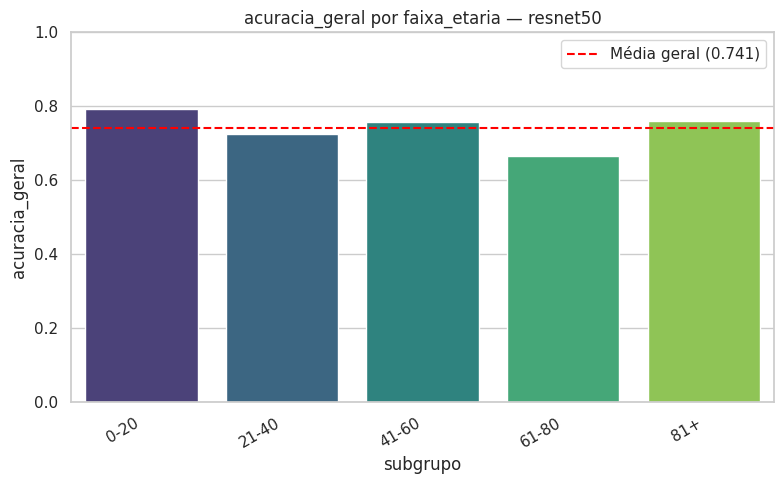

  Gráfico salvo em: /content/data/processed/equidade/equidade_faixa_etaria_acuracia_geral_resnet50.png


/tmp/ipykernel_960/2094831270.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_plot, x="subgrupo", y=coluna_metrica, palette="viridis")


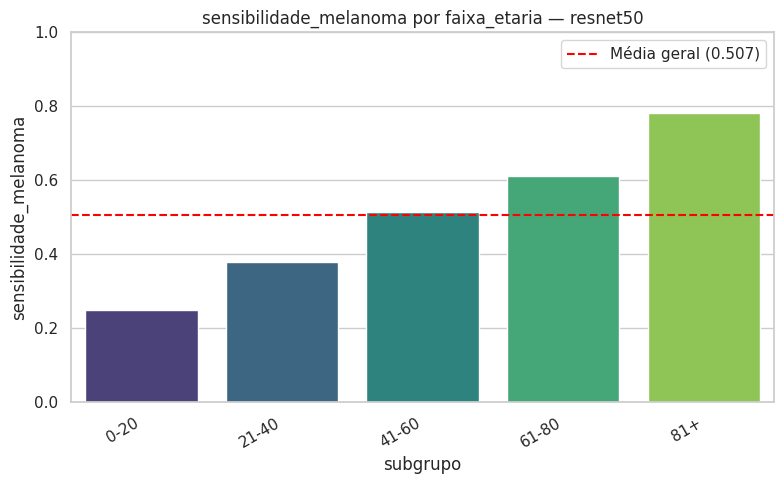

  Gráfico salvo em: /content/data/processed/equidade/equidade_faixa_etaria_sensibilidade_melanoma_resnet50.png

Análise de equidade: efficientnet_b0

--- Equidade por sexo (sex) ---
subgrupo  n_amostras_total  n_amostras_melanoma  acuracia_geral  sensibilidade_melanoma  confianca_media
  female              1613                  275          0.7390                  0.6036           0.8756
    male              1741                  313          0.7542                  0.6198           0.8810
  [OK] efficientnet_b0 | sexo | acuracia_geral: diferença máxima de 0.015 (dentro do limiar de 0.1)
  [OK] efficientnet_b0 | sexo | sensibilidade_melanoma: diferença máxima de 0.016 (dentro do limiar de 0.1)


/tmp/ipykernel_960/2094831270.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_plot, x="subgrupo", y=coluna_metrica, palette="viridis")


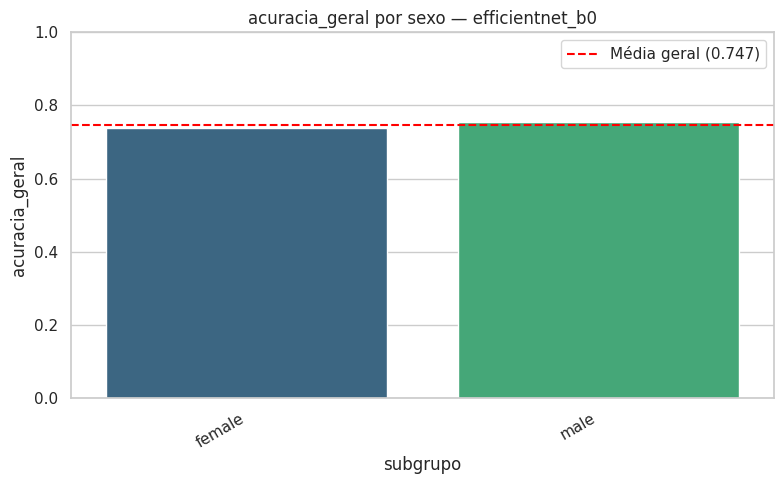

  Gráfico salvo em: /content/data/processed/equidade/equidade_sexo_acuracia_geral_efficientnet_b0.png


/tmp/ipykernel_960/2094831270.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_plot, x="subgrupo", y=coluna_metrica, palette="viridis")


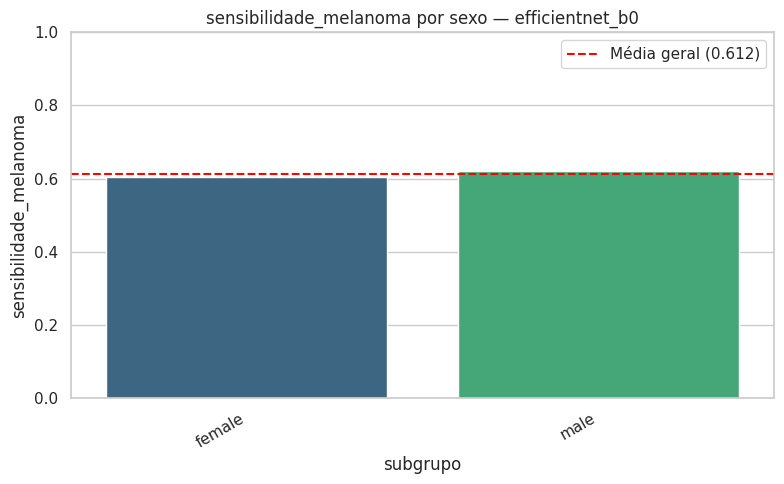

  Gráfico salvo em: /content/data/processed/equidade/equidade_sexo_sensibilidade_melanoma_efficientnet_b0.png

--- Equidade por faixa etária ---
subgrupo  n_amostras_total  n_amostras_melanoma  acuracia_geral  sensibilidade_melanoma  confianca_media
    0-20               126                    4          0.8651                  0.2500           0.9275
   21-40               788                   71          0.7513                  0.4507           0.8809
   41-60              1319                  218          0.7832                  0.5780           0.8830
   61-80               929                  249          0.6911                  0.6627           0.8655
     81+               176                   46          0.6477                  0.7826           0.8624
  [DISPARIDADE DETECTADA] efficientnet_b0 | faixa_etaria | acuracia_geral: 0-20=0.865 vs. 81+=0.648 (diferença de 0.217, acima do limiar de 0.1)
  [DISPARIDADE DETECTADA] efficientnet_b0 | faixa_etaria | sensibilidade_melanom

/tmp/ipykernel_960/2094831270.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_plot, x="subgrupo", y=coluna_metrica, palette="viridis")


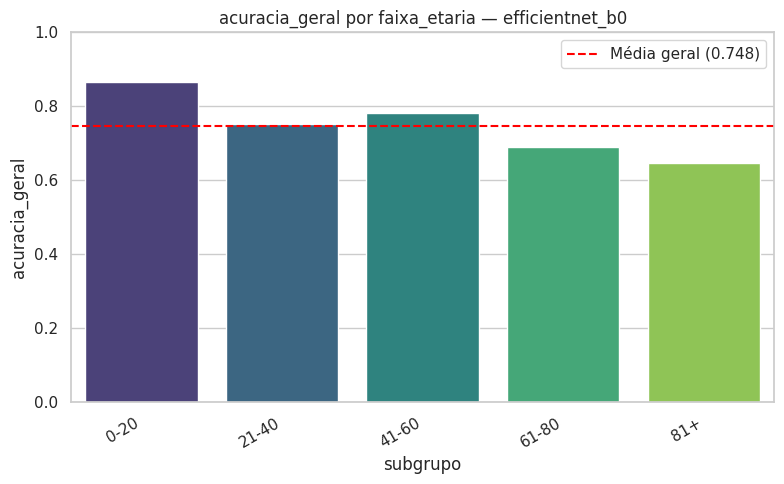

  Gráfico salvo em: /content/data/processed/equidade/equidade_faixa_etaria_acuracia_geral_efficientnet_b0.png


/tmp/ipykernel_960/2094831270.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_plot, x="subgrupo", y=coluna_metrica, palette="viridis")


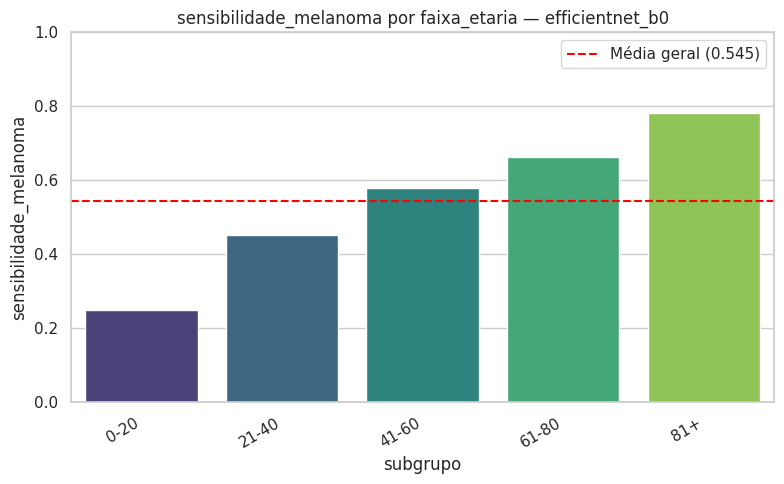

  Gráfico salvo em: /content/data/processed/equidade/equidade_faixa_etaria_sensibilidade_melanoma_efficientnet_b0.png

RESUMO CONSOLIDADO DE DISPARIDADES ENTRE SUBGRUPOS
    arquitetura subgrupo_analisado                metrica melhor_subgrupo  melhor_valor pior_subgrupo  pior_valor  diferenca  disparidade_relevante
       resnet50               sexo         acuracia_geral            male        0.7455        female      0.7068     0.0387                  False
       resnet50               sexo sensibilidade_melanoma            male        0.5719        female      0.5418     0.0301                  False
       resnet50       faixa_etaria         acuracia_geral            0-20        0.7937         61-80      0.6663     0.1274                   True
       resnet50       faixa_etaria sensibilidade_melanoma             81+        0.7826          0-20      0.2500     0.5326                   True
efficientnet_b0               sexo         acuracia_geral            male        0.7542   

In [ ]:
# ============================================================
# EXECUÇÃO
# ============================================================
if __name__ == "__main__":
    print("Carregando metadados do conjunto de teste...")
    df_test_meta = pd.read_csv(os.path.join(SAIDA_BASE, "test.csv"))

    col_idade = detectar_coluna(df_test_meta, ["idade", "age_approx", "age"])
    col_sexo = detectar_coluna(df_test_meta, ["sexo", "sex"])

    print(f"Coluna de idade detectada: {col_idade}")
    print(f"Coluna de sexo detectada: {col_sexo}")

    if col_idade is None and col_sexo is None:
        raise ValueError(
            "Nenhuma coluna de idade ou sexo encontrada em test.csv. "
            f"Colunas disponíveis: {df_test_meta.columns.tolist()}"
        )

    if col_idade:
        df_test_meta = preparar_faixas_etarias(df_test_meta, col_idade)

    print("\nCarregando DataLoaders...")
    _, _, test_loader, mapa_classes = criar_dataloaders()
    nomes_classes = sorted(mapa_classes, key=lambda k: mapa_classes[k])
    num_classes = len(nomes_classes)
    idx_melanoma = mapa_classes.get("melanoma")

    todas_disparidades = []

    for arquitetura in ARQUITETURAS:
        print("\n" + "=" * 60)
        print(f"Análise de equidade: {arquitetura}")
        print("=" * 60)

        modelo = carregar_modelo(arquitetura, num_classes)
        preds, rotulos, confiancas = coletar_predicoes_em_ordem(modelo, test_loader)

        # Confere que a quantidade bate com os metadados antes de juntar
        if len(preds) != len(df_test_meta):
            print(f"[ERRO] Quantidade de predições ({len(preds)}) difere da "
                  f"quantidade de linhas em test.csv ({len(df_test_meta)}). "
                  "Verifique se test.csv não foi alterado após gerar o DataLoader.")
            continue

        df_analise = df_test_meta.copy()
        df_analise["predicao"] = preds
        df_analise["rotulo_verdadeiro"] = rotulos
        df_analise["confianca"] = confiancas

        # --- Por sexo ---
        if col_sexo:
            print(f"\n--- Equidade por sexo ({col_sexo}) ---")
            df_metricas_sexo = calcular_metricas_por_subgrupo(
                df_analise, col_sexo, "melanoma", idx_melanoma
            )
            print(df_metricas_sexo.to_string(index=False))

            df_metricas_sexo.to_csv(
                os.path.join(SAIDA_EQUIDADE, f"metricas_sexo_{arquitetura}.csv"), index=False
            )

            disp = sinalizar_disparidades(df_metricas_sexo, "acuracia_geral", "sexo", arquitetura)
            if disp:
                todas_disparidades.append(disp)
            if idx_melanoma is not None:
                disp2 = sinalizar_disparidades(
                    df_metricas_sexo, "sensibilidade_melanoma", "sexo", arquitetura
                )
                if disp2:
                    todas_disparidades.append(disp2)

            plotar_metricas_por_subgrupo(df_metricas_sexo, "acuracia_geral", "sexo", arquitetura)
            if idx_melanoma is not None:
                plotar_metricas_por_subgrupo(
                    df_metricas_sexo, "sensibilidade_melanoma", "sexo", arquitetura
                )

        # --- Por faixa etária ---
        if col_idade:
            print(f"\n--- Equidade por faixa etária ---")
            df_metricas_idade = calcular_metricas_por_subgrupo(
                df_analise, "faixa_etaria", "melanoma", idx_melanoma
            )
            print(df_metricas_idade.to_string(index=False))

            df_metricas_idade.to_csv(
                os.path.join(SAIDA_EQUIDADE, f"metricas_idade_{arquitetura}.csv"), index=False
            )

            disp = sinalizar_disparidades(df_metricas_idade, "acuracia_geral", "faixa_etaria", arquitetura)
            if disp:
                todas_disparidades.append(disp)
            if idx_melanoma is not None:
                disp2 = sinalizar_disparidades(
                    df_metricas_idade, "sensibilidade_melanoma", "faixa_etaria", arquitetura
                )
                if disp2:
                    todas_disparidades.append(disp2)

            plotar_metricas_por_subgrupo(df_metricas_idade, "acuracia_geral", "faixa_etaria", arquitetura)
            if idx_melanoma is not None:
                plotar_metricas_por_subgrupo(
                    df_metricas_idade, "sensibilidade_melanoma", "faixa_etaria", arquitetura
                )

        del modelo
        torch.cuda.empty_cache()

    # ============================================================
    # RESUMO CONSOLIDADO DE DISPARIDADES
    # ============================================================
    print("\n" + "=" * 70)
    print("RESUMO CONSOLIDADO DE DISPARIDADES ENTRE SUBGRUPOS")
    print("=" * 70)
    df_disparidades = pd.DataFrame(todas_disparidades)
    if len(df_disparidades) > 0:
        print(df_disparidades.to_string(index=False))
        caminho_disp = os.path.join(SAIDA_EQUIDADE, "resumo_disparidades.csv")
        df_disparidades.to_csv(caminho_disp, index=False)
        print(f"\nResumo salvo em: {caminho_disp}")

        n_relevantes = df_disparidades["disparidade_relevante"].sum()
        print(f"\n{n_relevantes} de {len(df_disparidades)} comparações mostraram "
              f"disparidade acima do limiar de {LIMIAR_DISPARIDADE} "
              "— vale discutir essas no Capítulo 4/5 do TCC, cruzando com a "
              "limitação de representatividade da amostra já identificada no "
              "item 3.3 (Universo e Amostra).")
    else:
        print("Nenhuma disparidade calculada (verifique se as colunas demográficas existem).")

    print("\n" + "=" * 70)
    print("ARQUIVOS GERADOS EM:", SAIDA_EQUIDADE)
    print("=" * 70)
    for arquivo in sorted(os.listdir(SAIDA_EQUIDADE)):
        print(f"  - {arquivo}")

### EMPACOTAR RESULTADOS PARA DOWNLOAD

Gera um .zip com todas as figuras, tabelas e JSONs (sem checkpoints nem imagens).

In [ ]:
# ============================================================
# EMPACOTAR RESULTADOS (figuras, tabelas, JSONs) PARA DOWNLOAD
# Não inclui checkpoints (.pt) nem as imagens processadas.
# ============================================================
import shutil

def empacotar_resultados(nome_zip="/content/resultados_tcc"):
    pasta = "/content/resultados_tcc_pasta"
    shutil.rmtree(pasta, ignore_errors=True)
    os.makedirs(pasta, exist_ok=True)

    extensoes = (".png", ".csv", ".json")
    for raiz, dirs, arquivos in os.walk(SAIDA_BASE):
        # pula as pastas de imagens processadas (train/val/test e sem_dullrazor)
        dirs[:] = [d for d in dirs if d not in ("train", "val", "test", SUBPASTA_SEM_DR)]
        for arq in arquivos:
            if arq.lower().endswith(extensoes) and not arq.startswith(("train", "val", "test", "dataset_limpo")):
                rel = os.path.relpath(raiz, SAIDA_BASE)
                destino = os.path.join(pasta, rel)
                os.makedirs(destino, exist_ok=True)
                shutil.copy2(os.path.join(raiz, arq), destino)

    caminho = shutil.make_archive(nome_zip, "zip", pasta)
    print(f"Arquivo gerado: {caminho} ({os.path.getsize(caminho) / 1e6:.1f} MB)")
    try:
        from google.colab import files
        files.download(caminho)
    except ImportError:
        print("(fora do Colab: baixe o arquivo manualmente)")

if __name__ == "__main__":
    empacotar_resultados()

Arquivo gerado: /content/resultados_tcc.zip (30.3 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>